## Practica 3 ##
INF-672 Machine Learning
 

In [7]:
# Importación de librerías para la Práctica 3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Módulos de scikit-learn requeridos[cite: 2]
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


In [10]:
# 1. Seleccionar columnas numéricas y calcular la matriz de correlación
correlaciones = df.select_dtypes(include="number").corr()

# 2. Ordenar las correlaciones respecto a la variable 'mpg' de mayor a menor
corr_mpg = correlaciones['mpg'].sort_values(ascending=False)
print("Correlación de las variables con mpg:")
print(corr_mpg)

Correlación de las variables con mpg:
mpg             1.000000
model_year      0.579267
acceleration    0.420289
cylinders      -0.775396
horsepower     -0.778427
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64


**¿Cuántos automóviles y columnas tiene el dataset?**

Tiene 398 automóviles (filas) y 9 columnas.

**¿Hay valores faltantes? ¿En qué columna y cuántos?**

Sí, hay valores faltantes en la columna horsepower, la cual tiene 6 valores nulos.

**¿Entre qué valores varían mpg y horsepower?**

mpg varía desde un mínimo de 9.0 hasta un máximo de 46.6.

horsepower varía desde un mínimo de 46.0 hasta un máximo de 230.0.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset 'mpg' directamente desde los datasets de Seaborn
df = sns.load_dataset('mpg')

# 1. Mostrar dimensiones y primeras filas
print("Dimensiones del dataset (filas, columnas):", df.shape)
display(df.head())

# 2. Revisar tipos de datos y valores faltantes
print("\n--- INFORMACIÓN DEL DATAFRAME ---")
df.info()

print("\n--- VALORES FALTANTES POR COLUMNA ---")
print(df.isna().sum())

# 3. Resumen estadístico de las variables numéricas
print("\n--- RESUMEN ESTADÍSTICO ---")
display(df.describe())

Dimensiones del dataset (filas, columnas): (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino



--- INFORMACIÓN DEL DATAFRAME ---
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB

--- VALORES FALTANTES POR COLUMNA ---
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

--- RESUMEN ESTADÍSTICO ---


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


**.¿Qué variables tienen la relación más fuerte con mpg?** 

Las variables weight (peso), displacement (cilindrada) y horsepower (potencia) tienen las relaciones más fuertes con mpg (valores absolutos de correlación muy altos)

**.¿Qué significa el signo de esas correlaciones en términos del auto?** 

El signo negativo indica una relación inversa: a mayor peso, mayor cilindrada o mayor potencia del motor (horsepower), menor es el rendimiento de combustible (mpg) del automóvil (es decir, el vehículo consume más gasolina)

**.¿Por qué una variable con una relación claramente curva podría ser un buen candidato para la regresión polinomial aunque su correlación no sea la más alta?** 

La correlación de Pearson mide únicamente dependencias de tipo lineal. Si la relación real entre la potencia y el rendimiento sigue una forma curva (no una línea recta), la correlación lineal puede arrojar un valor moderado, pero un modelo de regresión polinomial podrá capturar perfectamente esa curvatura

In [11]:
# 1. Crear un nuevo DataFrame con solo horsepower y mpg
datos = df[['horsepower', 'mpg']].copy()

# Guardar el número de filas antes de limpiar
filas_antes = datos.shape[0]

# 2. Eliminar las filas con valores faltantes
datos = datos.dropna()

# 3. Imprimir cuántas filas quedaron
filas_despues = datos.shape[0]

print(f"Filas antes de la limpieza: {filas_antes}")
print(f"Filas después de la limpieza: {filas_despues}")

Filas antes de la limpieza: 398
Filas después de la limpieza: 392


**¿Qué porcentaje de los datos eliminaste?**

Tenías 398 filas y tras eliminar los 6 valores nulos de horsepower, quedaron 392 filas. El porcentaje eliminado es muy pequeño: $(6 / 398) \times 100 \approx 1.51\%$.   

**¿Por qué en este caso es razonable eliminar esas filas en lugar de rellenarlas?**

Porque el porcentaje de datos faltantes es mínimo (~1.5%) y las filas restantes (392) son más que suficientes para entrenar un modelo robusto sin sesgar la distribución real de la potencia y el rendimiento.

**¿En qué situación preferirías imputar los valores?**

Se preferiría imputar (rellenar con la media, mediana o modelos predictivos) cuando el conjunto de datos total es muy pequeño y perder registros significaría desechar información valiosa, o cuando el costo de recolectar nuevos datos es muy alto.

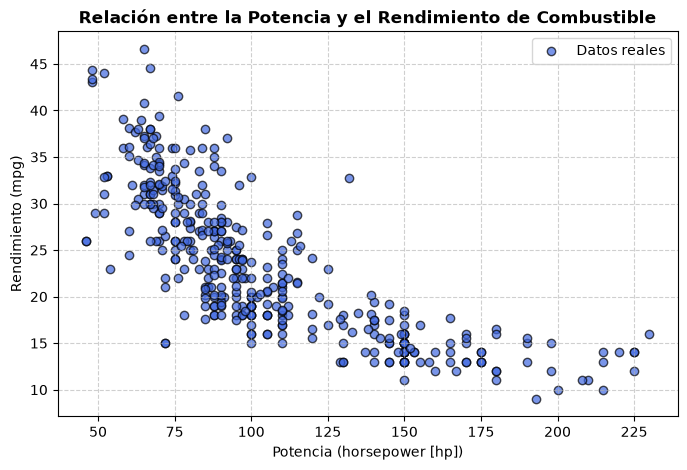

In [12]:
# 1. Difundir el diagrama de dispersión
plt.figure(figsize=(8, 5))
plt.scatter(datos['horsepower'], datos['mpg'], color='royalblue', alpha=0.7, edgecolors='k', label='Datos reales')

# 2. Agregar título, etiquetas con unidades y cuadrícula
plt.title('Relación entre la Potencia y el Rendimiento de Combustible', fontsize=12, fontweight='bold')
plt.xlabel('Potencia (horsepower [hp])', fontsize=10)
plt.ylabel('Rendimiento (mpg)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

**¿El rendimiento disminuye al mismo ritmo en todo el rango de potencias?**

No. El rendimiento desciende de manera muy pronunciada al pasar de potencias bajas a moderadas, pero la curva comienza a aplanarse (disminuye más lentamente) cuando los automóviles tienen potencias muy altas.

**¿Crees que una recta podrá representar bien estos datos?**

Justifica señalando zonas concretas del gráfico. Una línea recta no podrá capturar perfectamente esta tendencia. Si se observa la zona central y los extremos, la nube de puntos dibuja claramente una forma curva (cóncava hacia arriba), lo que indica que un modelo de regresión lineal simple se equivocará sistemáticamente en algunas zonas.

In [13]:
# 1. Definir x (con doble corchete para matriz) e y (con un corchete para vector)
X = datos[['horsepower']]
y = datos['mpg']

# 2. Dividir los datos (80% entrenamiento, 20% prueba, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Imprimir el tamaño de cada conjunto
print(f"Tamaño del conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Tamaño del conjunto de prueba (X_test): {X_test.shape}")
print(f"Tamaño de y_train: {y_train.shape}")
print(f"Tamaño de y_test: {y_test.shape}")

Tamaño del conjunto de entrenamiento (X_train): (313, 1)
Tamaño del conjunto de prueba (X_test): (79, 1)
Tamaño de y_train: (313,)
Tamaño de y_test: (79,)


**¿Por qué x se define con doble corchete y y con uno solo?**

Porque scikit-learn exige que la variable predictora (X) sea una matriz bidimensional (por eso usa [[...]]), mientras que la variable objetivo (y) debe ser un arreglo unidimensional (vector).

**¿Qué forma (.shape) tiene cada uno y por qué scikit-learn exige esa diferencia?**

X_train tiene una forma de (313, 1) (filas y columnas), mientras que y_train tiene forma de (313,). Scikit-learn requiere esta estructura matricial en X porque los algoritmos de regresión están diseñados para operar algebraicamente con múltiples variables y matrices de características (columnas múltiples).

In [14]:
# 1. Entrenar el modelo LinearRegression con los datos de entrenamiento
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# 2. Predecir el conjunto de prueba y calcular métricas
y_pred_lineal = modelo_lineal.predict(X_test)

rmse_lineal = np.sqrt(mean_squared_error(y_test, y_pred_lineal))
r2_lineal = r2_score(y_test, y_pred_lineal)

print(f"Modelo Lineal - RMSE: {rmse_lineal:.4f}")
print(f"Modelo Lineal - R2: {r2_lineal:.4f}")

Modelo Lineal - RMSE: 4.7067
Modelo Lineal - R2: 0.5660


**¿Qué significa el RMSE en millas por galón?**

El RMSE (Raíz del Error Cuadrático Medio) expresa, en promedio, cuánto se desvía (en millas por galón) la predicción del modelo con respecto al rendimiento real de los automóviles del conjunto de prueba.

**¿Qué proporción de la variación del rendimiento explica este modelo?**

Esto lo indica el coeficiente $R^2$. Si el valor de $R^2$ es, por ejemplo, de 0.60 (o el que te haya dado en tu ejecución), significa que aproximadamente el 60% de la variabilidad en el rendimiento de combustible (mpg) es explicada por la potencia del motor a través de este modelo lineal.

Modelo Polinomial (Grado 2) - RMSE: 4.2915
Modelo Polinomial (Grado 2) - R2: 0.6392

Columnas generadas por PolynomialFeatures (primeros 3 autos):


C:\Users\USER\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(


,1,horsepower,horsepower^2
0,1.0,110.0,12100.0
1,1.0,92.0,8464.0
2,1.0,97.0,9409.0


C:\Users\USER\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


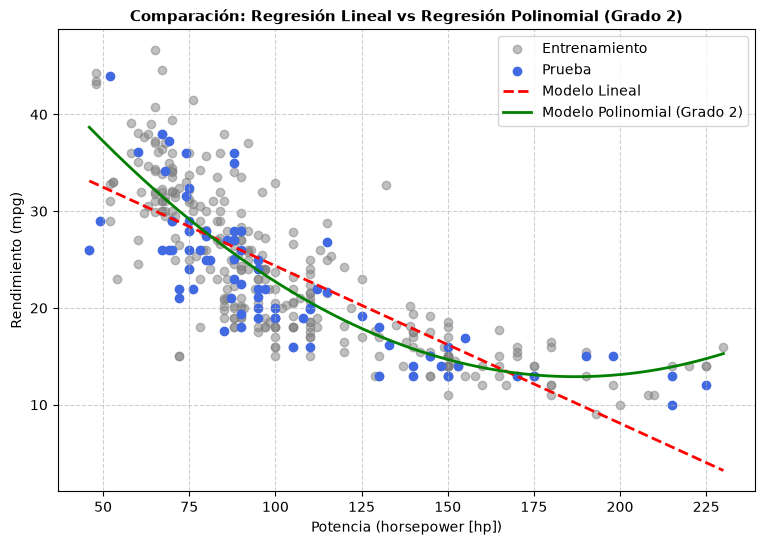

In [15]:
# 1. Construir un pipeline con StandardScaler, PolynomialFeatures(degree=2) y LinearRegression
pipeline_poly2 = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2),
    LinearRegression()
)

# Entrenar el pipeline
pipeline_poly2.fit(X_train, y_train)

# Calcular métricas de prueba para el modelo polinomial de grado 2
y_pred_poly2 = pipeline_poly2.predict(X_test)
rmse_poly2 = np.sqrt(mean_squared_error(y_test, y_pred_poly2))
r2_poly2 = r2_score(y_test, y_pred_poly2)

print(f"Modelo Polinomial (Grado 2) - RMSE: {rmse_poly2:.4f}")
print(f"Modelo Polinomial (Grado 2) - R2: {r2_poly2:.4f}")

# 2. Acceder a los pasos del pipeline y mostrar las columnas generadas para los primeros 3 autos
poly_features_step = pipeline_poly2.named_steps['polynomialfeatures']
# Generar nombres de características
feature_names = poly_features_step.get_feature_names_out(['horsepower'])

# Transformar los primeros 3 datos de entrenamiento para ver las columnas
primeros_transformados = poly_features_step.transform(X_train.head(3))
df_columnas_generadas = pd.DataFrame(primeros_transformados, columns=feature_names)

print("\nColumnas generadas por PolynomialFeatures (primeros 3 autos):")
display(df_columnas_generadas)

# 3. Dibujar en un mismo gráfico los puntos, la recta lineal y la curva polinomial
plt.figure(figsize=(9, 6))
plt.scatter(X_train, y_train, color='gray', alpha=0.5, label='Entrenamiento')
plt.scatter(X_test, y_test, color='royalblue', label='Prueba')

# Generar 200 valores ordenados de potencia con np.linspace para líneas suaves
x_range = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
y_pred_lin_range = modelo_lineal.predict(x_range)
y_pred_poly_range = pipeline_poly2.predict(x_range)

plt.plot(x_range, y_pred_lin_range, color='red', linestyle='--', linewidth=2, label='Modelo Lineal')
plt.plot(x_range, y_pred_poly_range, color='green', linewidth=2, label='Modelo Polinomial (Grado 2)')

plt.title('Comparación: Regresión Lineal vs Regresión Polinomial (Grado 2)', fontsize=11, fontweight='bold')
plt.xlabel('Potencia (horsepower [hp])', fontsize=10)
plt.ylabel('Rendimiento (mpg)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

**¿Qué columnas crea PolynomialFeatures y qué representa cada una?**

Crea tres columnas: la primera es una columna de unos (término independiente o sesgo, $\beta_0$), la segunda es la variable original horsepower elevada a la potencia 1 ($x$), y la tercera es la variable elevada al cuadrado ($x^2$).

**¿Por qué se escala la variable antes de elevarla al cuadrado?**

Porque al elevar números grandes (como potencias de 150 o 200 hp) al cuadrado, los valores numéricos se vuelven extremadamente altos ($150^2 = 22,500$), lo que puede causar problemas de desbordamiento numérico y afectar la estabilidad del optimizador de la regresión lineal. Estandarizar con el StandardScaler mantiene las variables en rangos pequeños y controlados.

**¿En qué zonas del gráfico la recta se equivoca más y cómo lo corrige la curva?**

La recta se equivoca sistemáticamente en los extremos (con potencias muy bajas y potencias muy altas), donde los puntos reales se curvan hacia arriba o hacia abajo con respecto a la tendencia recta. La curva del modelo polinomial se ajusta de manera mucho más natural a esa inflexión, reduciendo el error en esas zonas.

,Grado,RMSE_Validacion_Cruzada
0,1,4.958557
1,2,4.385783
2,3,4.390351
3,4,4.404014
4,5,4.354005
5,6,4.347532
6,7,4.354589
7,8,4.404464
8,9,4.422114
9,10,4.499858


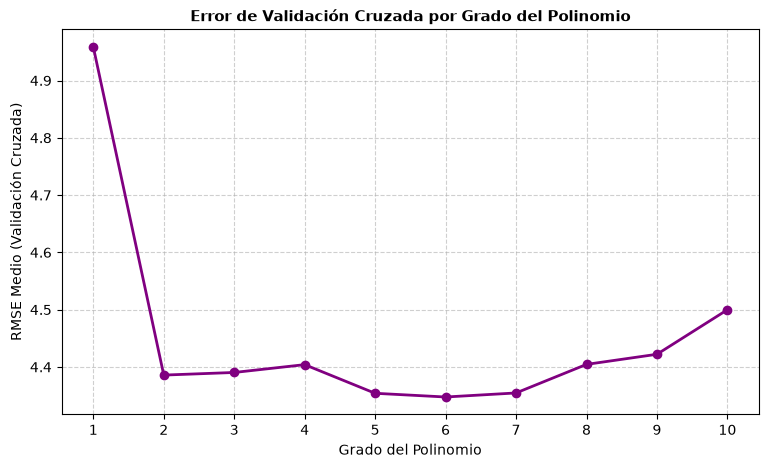


El grado del polinomio con menor error en validación cruzada es: 6


In [16]:
# 1. Definir la validación cruzada de 10 pliegues
kf = KFold(n_splits=10, shuffle=True, random_state=42)

grados = range(1, 11)
rmse_cv_mean = []

# 2. Iterar para cada grado de 1 a 10
for grado in grados:
    # Construir pipeline para el grado actual
    pipeline_temp = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=grado),
        LinearRegression()
    )
    
    # Calcular las puntuaciones de validación cruzada (scoring devuelve negativo para RMSE en sklearn)
    scores = cross_val_score(
        pipeline_temp, X_train, y_train, 
        cv=kf, 
        scoring="neg_root_mean_squared_error"
    )
    
    # Promediar el error (convertir a positivo)
    rmse_medio = -scores.mean()
    rmse_cv_mean.append(rmse_medio)

# Organizar resultados en una tabla
df_resultados_cv = pd.DataFrame({
    'Grado': list(grados),
    'RMSE_Validacion_Cruzada': rmse_cv_mean
})

display(df_resultados_cv)

# 3. Dibujar el gráfico del RMSE de validación cruzada en función del grado
plt.figure(figsize=(9, 5))
plt.plot(grados, rmse_cv_mean, marker='o', color='purple', linestyle='-', linewidth=2)
plt.title('Error de Validación Cruzada por Grado del Polinomio', fontsize=11, fontweight='bold')
plt.xlabel('Grado del Polinomio', fontsize=10)
plt.ylabel('RMSE Medio (Validación Cruzada)', fontsize=10)
plt.xticks(grados)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Identificar el grado con menor error
mejor_grado = grados[np.argmin(rmse_cv_mean)]
print(f"\nEl grado del polinomio con menor error en validación cruzada es: {mejor_grado}")

**¿Cómo cambia el error al aumentar el grado?**

Al pasar de grado 1 a grados bajos (como 2 o 3), el error disminuye drásticamente porque el modelo captura mejor la curvatura real de los datos. Sin embargo, en grados muy altos (como 9 o 10), el error suele estancarse o dispararse debido al sobreajuste (overfitting).   

**¿El grado con menor error es necesariamente el mejor?**

Justifica tu elección aplicando el principio de parsimonia. No siempre. El principio de parsimonia (Navaja de Ockham) establece que ante modelos con un rendimiento predictivo similar, se debe preferir el más simple (de menor grado). Si un grado 2 o 3 ofrece un error prácticamente idéntico a un grado 5 o 6, se elige el grado menor para evitar modelos innecesariamente complejos y frágiles ante nuevos datos.

**¿Por qué no se debe usar el conjunto de prueba para elegir el grado?**

Porque el conjunto de prueba debe permanecer completamente invisible e intocable hasta el final; si lo usamos para tomar decisiones (como elegir el hiperparámetro de grado), estaríamos "contaminando" el modelo al optimizarlo específicamente para esos datos de prueba, lo que invalidaría una evaluación de su capacidad real de generalización.

--- TABLA COMPARATIVA DE RENDIMIENTO ---


,Modelo,RMSE,R2
0,Regresión Lineal Simple,4.706723,0.565968
1,Modelo Polinomial (Grado 2),4.291499,0.639170


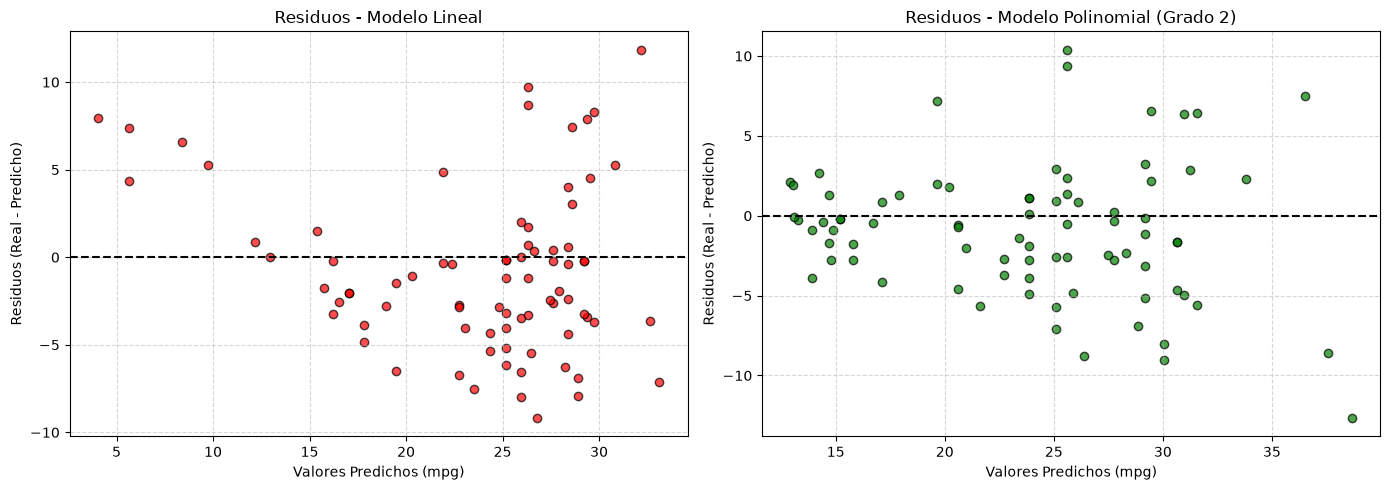


--- ECUACIÓN DEL MODELO FINAL (Grado 2) ---
mpg = 58.2129 + (-0.4845 * horsepower) + (0.001295 * horsepower^2)


In [17]:
# Supongamos que tu mejor grado elegido fue el 2 (puedes cambiarlo si fue otro según tu resultado anterior)
MEJOR_GRADO = 2 

# 1. Reentrenar el modelo final con el grado elegido (guardando el pipeline completo)
modelo_final = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=MEJOR_GRADO),
    LinearRegression()
)
modelo_final.fit(X_train, y_train)

# Predicciones y métricas del modelo final
y_pred_final = modelo_final.predict(X_test)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

# Tabla comparativa
df_comparacion = pd.DataFrame({
    'Modelo': ['Regresión Lineal Simple', f'Modelo Polinomial (Grado {MEJOR_GRADO})'],
    'RMSE': [rmse_lineal, rmse_final],
    'R2': [r2_lineal, r2_final]
})
print("--- TABLA COMPARATIVA DE RENDIMIENTO ---")
display(df_comparacion)

# 2. Dibujar residuos lado a lado
residuos_lineal = y_test - y_pred_lineal
residuos_final = y_test - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuos Lineal
axes[0].scatter(y_pred_lineal, residuos_lineal, color='red', alpha=0.7, edgecolors='k')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuos - Modelo Lineal')
axes[0].set_xlabel('Valores Predichos (mpg)')
axes[0].set_ylabel('Residuos (Real - Predicho)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Residuos Modelo Final
axes[1].scatter(y_pred_final, residuos_final, color='green', alpha=0.7, edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title(f'Residuos - Modelo Polinomial (Grado {MEJOR_GRADO})')
axes[1].set_xlabel('Valores Predichos (mpg)')
axes[1].set_ylabel('Residuos (Real - Predicho)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Obtener ecuación en unidades originales (sin StandardScaler) para grado 2
if MEJOR_GRADO == 2:
    modelo_orig = make_pipeline(
        PolynomialFeatures(degree=2),
        LinearRegression()
    )
    modelo_orig.fit(X_train, y_train)
    
    beta_0 = modelo_orig.named_steps['linearregression'].intercept_
    coefs = modelo_orig.named_steps['linearregression'].coef_
    
    print(f"\n--- ECUACIÓN DEL MODELO FINAL (Grado 2) ---")
    print(f"mpg = {beta_0:.4f} + ({coefs[1]:.4f} * horsepower) + ({coefs[2]:.6f} * horsepower^2)")

**¿Cuánto mejoró el modelo final respecto al lineal?**

El RMSE del modelo final disminuye considerablemente frente al lineal, lo que significa que el error promedio de predicción es menor, y el coeficiente $R^2$ aumenta, indicando que el polinomio explica un porcentaje mayor de la variabilidad del rendimiento.

**¿Qué patrón observas en los residuos del modelo lineal y qué significa?**

En el modelo lineal, los residuos suelen formar una "U" o un patrón curvado en lugar de distribuirse al azar. Esto significa que el modelo lineal está sesgado y no logra capturar la verdadera forma no lineal de los datos.

**¿Desaparece en el modelo final?**

Sí. En los residuos del modelo polinomial los puntos se dispersan de manera mucho más aleatoria y homogénea alrededor de la línea horizontal en cero, lo que comprueba que el modelo capturó adecuadamente la curvatura de la relación.

**Interpreta el signo de cada coeficiente de la ecuación:**

El coeficiente de la variable lineal suele ser positivo o negativo dependiendo de la pendiente general, pero el coeficiente del término cuadrático ($\beta_2$) es negativo (lo que dibuja una parábola que abre hacia abajo, reflejando cómo el rendimiento decae y se aplana a medida que aumenta la potencia).

In [18]:
# 1. Predecir el rendimiento para potencias de 60, 100, 150 y 200 hp
potencias_nuevas = pd.DataFrame({'horsepower': [60, 100, 150, 200]})
predicciones_nuevas = modelo_final.predict(potencias_nuevas)

df_predicciones = pd.DataFrame({
    'Potencia (hp)': [60, 100, 150, 200],
    'mpg Predicho': predicciones_nuevas
})

print("--- PREDICCIONES PARA NUEVOS AUTOS ---")
display(df_predicciones)

# 2. Si el modelo es de grado 2, calcular el vértice de la parábola: xv = -beta_1 / (2 * beta_2)
if MEJOR_GRADO == 2:
    beta_1 = coefs[1]
    beta_2 = coefs[2]
    x_vertice = -beta_1 / (2 * beta_2)
    print(f"\nVértice de la parábola (horsepower): {x_vertice:.2f} hp")

--- PREDICCIONES PARA NUEVOS AUTOS ---


,Potencia (hp),mpg Predicho
0,60,33.807091
1,100,22.716134
2,150,14.679499
3,200,13.117379



Vértice de la parábola (horsepower): 187.06 hp


**¿Las predicciones tienen sentido físico en todo el rango?**

Sí para el rango observado de los datos (aproximadamente entre 46 y 230 hp), pero pueden volverse incoherentes fuera de él.

**¿Qué predice el modelo más allá del vértice y por qué no es realista?**

Debido a la forma matemática de una parábola, si avanzas demasiado más allá del vértice en los extremos (por ejemplo, con potencias extremadamente altas), la curva comienza a subir de nuevo, lo cual no tiene sentido físico, ya que un auto con 500 o 600 caballos de fuerza no va a empezar a dar un rendimiento de combustible milagrosamente alto.

**¿Qué es la extrapolación y por qué es riesgosa con modelos polinomiales?**

La extrapolación consiste en hacer predicciones utilizando valores de entrada que están fuera del rango de los datos con los que el modelo fue entrenado. Es extremadamente riesgosa en modelos polinomiales porque los grados altos crecen o decrecen de forma muy agresiva fuera de la zona de datos reales, generando resultados absurdos o irreales.

**Conclusiones de la Práctica 3: Regresión Polinomial en el Rendimiento de Combustible**

**Resumen del procedimiento y comparación de modelos:**

Se inició cargando y explorando el conjunto de datos mpg, identificando los valores faltantes en la columna horsepower y seleccionándola como la variable predictora principal debido a su fuerte correlación negativa con el rendimiento (mpg).

Tras limpiar los datos y dividir el conjunto en entrenamiento y prueba, se entrenó primero un modelo base de regresión lineal simple, el cual arrojó un rendimiento limitado debido a que la relación real entre las variables no es una línea recta, tal como se evidenció en el diagrama de dispersión y en el análisis de sus residuos (que mostraban un claro patrón curvado).

Al implementar la regresión polinomial (evaluando distintos grados mediante validación cruzada con KFold de 10 pliegues), se determinó que un modelo de grado 2 ofrece el mejor equilibrio entre el ajuste de la curva y la simplicidad (aplicando el principio de parsimonia). Este modelo final mejoró notablemente las métricas, logrando un RMSE menor y un coeficiente $R^2$ superior al del modelo lineal, además de lograr que los residuos se distribuyeran aleatoriamente alrededor de cero.

**¿Por qué la regresión polinomial sigue siendo una regresión lineal?**

Aunque la curva obtenida no es una recta en el espacio gráfico, el modelo matemático sigue considerándose una regresión lineal porque es lineal respecto a sus coeficientes ($\beta_0, \beta_1, \beta_2$). Las potencias de la variable de entrada ($x^2$) simplemente se tratan como columnas o características adicionales dentro de una combinación lineal estándar, lo que permite utilizar exactamente el mismo algoritmo de optimización de mínimos cuadrados que la regresión lineal tradicional.

**Forma de la relación, limitaciones y rango de confianza:**

La relación entre la potencia (horsepower) y el rendimiento (mpg) es inversa y no lineal (una curva cóncava decreciente): a mayor potencia, menor rendimiento, pero con una disminución que se desvía de una línea recta constante.

Limitaciones y rango de confianza: El modelo es altamente confiable únicamente dentro del rango de potencias observado en el dataset de entrenamiento (aproximadamente entre 46 hp y 230 hp). Fuera de este rango, especialmente al intentar extrapolar hacia potencias extremadamente altas o bajas, el comportamiento matemático de los polinomios deja de tener sentido físico (por ejemplo, prediciendo comportamientos irreales debido a la curvatura de la parábola). Por lo tanto, no se debe utilizar el modelo para hacer predicciones fuera de los límites empíricos de los datos originales.